In [10]:
import glob
import os
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Quét tìm file .h5 ở cả thư mục hiện tại lẫn thư mục cha (phòng trường hợp file notebook nằm ở ngoài hoặc trong thư mục notebooks/)
h5_files = sorted(
    glob.glob('../streams/**/*.h5*', recursive=True)
    + glob.glob('../data/**/*.h5*', recursive=True)
    + glob.glob('streams/**/*.h5*', recursive=True)
    + glob.glob('data/**/*.h5*', recursive=True)
)

print(f'Tìm thấy tổng cộng {len(h5_files)} file HDF5.')
for f in h5_files[:5]:
  print(' -', f)

Tìm thấy tổng cộng 19 file HDF5.
 - ../data\interim\starter_extra.h5
 - ../streams\train\stream_00.h5
 - ../streams\train\stream_01.h5
 - ../streams\train\stream_02.h5
 - ../streams\train\stream_03.h5


In [11]:
sample_file = stream_files[0]
print(f"Đang phân tích: {sample_file}\n" + "=" * 50)

with h5py.File(sample_file, "r") as f:
    # 1. Toàn bộ cấu trúc file (keys + attributes)
    print("Keys      :", list(f.keys()))
    print("Attributes:", dict(f.attrs))

    print("\n--- Chi tiết từng dataset ---")
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name}: shape={obj.shape}, dtype={obj.dtype}")
        else:
            print(f"[Group] {name}")
    f.visititems(show)

    # 2. radar_serials (có thể nằm ở key hoặc attrs)
    if "radar_serials" in f:
        serials = f["radar_serials"][:]
    else:
        serials = f.attrs.get("radar_serials", "Không tìm thấy")
    print("\nradar_serials:", serials)

    # 3. Trục thời gian t
    t = f["t"][:]
    dt = np.diff(t)
    print("\n5 mốc t đầu:", t[:5])
    print("t đầu / cuối:", t[0], "/", t[-1])
    print("dt trung vị:", np.median(dt))
    print("Tần số ước tính:", 1 / np.median(dt), "Hz")

    # 4. Xem 1 mẫu cir (chỉ đọc 1 lát cắt, không load hết vào RAM)
    cir = f["cir"]
    print("\ncir shape:", cir.shape, "| dtype:", cir.dtype)
    print("Lát cắt đầu tiên:", cir[:, 0, :].shape)

Đang phân tích: ../streams\train\stream_00.h5
Keys      : ['cir', 'radar_serials', 't']
Attributes: {'fade_s': np.float64(0.2), 'seed': np.int64(2027), 'split': 'train', 'stream_index': np.int64(0)}

--- Chi tiết từng dataset ---
cir: shape=(3, 88117, 368), dtype=float32
radar_serials: shape=(3,), dtype=int32
t: shape=(88117,), dtype=float64

radar_serials: [29171 29444 30722]

5 mốc t đầu: [0.   0.02 0.04 0.06 0.08]
t đầu / cuối: 0.0 / 1762.32
dt trung vị: 0.01999999999998181
Tần số ước tính: 50.000000000045475 Hz

cir shape: (3, 88117, 368) | dtype: float32
Lát cắt đầu tiên: (3, 368)


In [12]:
records = []

for fpath in stream_files:
    size_mb = os.path.getsize(fpath) / (1024 ** 2)

    with h5py.File(fpath, "r") as f:
        cir_shape = f["cir"].shape
        t = f["t"][:]
        n_radar, n_frames, n_bins = cir_shape
        duration_s = float(t[-1] - t[0])
        fps = (n_frames - 1) / duration_s if duration_s > 0 else 0

        records.append({
            "Stream": os.path.basename(fpath),
            "Split": str(f.attrs["split"]),
            "Stream index": int(f.attrs["stream_index"]),
            "Shape CIR": str(cir_shape),
            "Radars": n_radar,
            "Frames (T)": n_frames,
            "Range bins": n_bins,
            "Duration (s)": round(duration_s, 2),
            "Duration (min)": round(duration_s / 60, 2),
            "Effective Hz": round(fps, 2),
            "Size (MB)": round(size_mb, 2),
        })

df_streams = pd.DataFrame(records)
display(df_streams)

,Stream,Split,Stream index,Shape CIR,Radars,Frames (T),Range bins,Duration (s),Duration (min),Effective Hz,Size (MB)
0,stream_00.h5,train,0,"(3, 88117, 368)",3,88117,368,1762.32,29.37,50.0,379.71
1,stream_01.h5,train,1,"(3, 88147, 368)",3,88147,368,1762.92,29.38,50.0,379.71
2,stream_02.h5,train,2,"(3, 85923, 368)",3,85923,368,1718.44,28.64,50.0,379.69
3,stream_03.h5,train,3,"(3, 88085, 368)",3,88085,368,1761.68,29.36,50.0,379.71
4,stream_04.h5,train,4,"(3, 88243, 368)",3,88243,368,1764.84,29.41,50.0,379.71
5,stream_05.h5,train,5,"(3, 88327, 368)",3,88327,368,1766.52,29.44,50.0,379.71
6,stream_06.h5,train,6,"(3, 88356, 368)",3,88356,368,1767.10,29.45,50.0,379.71
7,stream_07.h5,train,7,"(3, 88311, 368)",3,88311,368,1766.20,29.44,50.0,379.71
8,stream_08.h5,train,8,"(3, 88371, 368)",3,88371,368,1767.40,29.46,50.0,379.71
9,stream_09.h5,train,9,"(3, 88103, 368)",3,88103,368,1762.04,29.37,50.0,379.71


In [13]:
df_summary = (
    df_streams.groupby("Split")
    .agg(
        So_stream=("Stream", "count"),
        Tong_frames=("Frames (T)", "sum"),
        Tong_gio=("Duration (min)", lambda x: round(x.sum() / 60, 2)),
        TB_phut=("Duration (min)", lambda x: round(x.mean(), 2)),
        Min_phut=("Duration (min)", "min"),
        Max_phut=("Duration (min)", "max"),
        Tong_GB=("Size (MB)", lambda x: round(x.sum() / 1024, 2)),
        Hz_TB=("Effective Hz", "mean"),
    )
    .reset_index()
)

# Tỷ lệ thời lượng Train / Val
tong = df_summary["Tong_gio"].sum()
df_summary["Ty_le_thoi_luong_%"] = (df_summary["Tong_gio"] / tong * 100).round(1)

display(df_summary)

,Split,So_stream,Tong_frames,Tong_gio,TB_phut,Min_phut,Max_phut,Tong_GB,Hz_TB,Ty_le_thoi_luong_%
0,train,13,1112735,6.18,28.53,18.93,29.46,4.70,50.0,75.1
1,val,5,368790,2.05,24.59,5.19,29.51,1.57,50.0,24.9


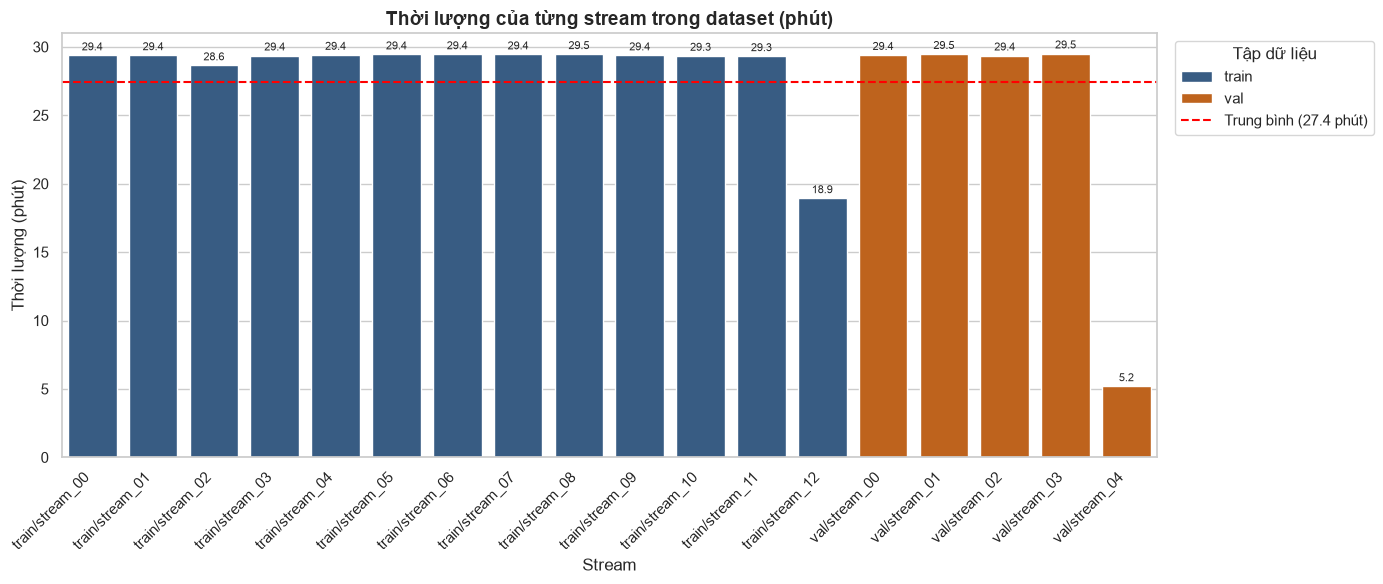

In [14]:
df_streams["Label"] = df_streams["Split"] + "/" + df_streams["Stream"].str.replace(".h5", "", regex=False)

os.makedirs("../reports", exist_ok=True)   # tạo thư mục nếu chưa có

plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=df_streams,
    x="Label",
    y="Duration (min)",
    hue="Split",
    dodge=False,
    palette={"train": "#2b5c8f", "val": "#d95f02"},
)

mean_dur = df_streams["Duration (min)"].mean()
plt.axhline(mean_dur, color="red", linestyle="--", label=f"Trung bình ({mean_dur:.1f} phút)")

plt.title("Thời lượng của từng stream trong dataset (phút)", fontsize=14, fontweight="bold")
plt.xlabel("Stream", fontsize=12)
plt.ylabel("Thời lượng (phút)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Tập dữ liệu", loc="upper left", bbox_to_anchor=(1.01, 1))
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8, padding=2)
plt.tight_layout()
plt.savefig("../reports/stream_durations.png", dpi=300)
plt.show()

## Cấu trúc CIR (3, T, 368)

Dữ liệu `cir` có kiểu float32, mỗi stream là một mảng 3 chiều:

- **Chiều 0 (3): số radar.** Ba radar UWB ghi đồng thời; thứ tự ba hàng khớp với `radar_serials` (ví dụ stream_00: 29171, 29444, 30722).
- **Chiều 1 (T): số frame theo thời gian.** Lấy mẫu 50 Hz (0.02 s/frame). Mảng `t` có shape `(T,)`, tính bằng giây, bắt đầu từ 0 và dùng chung cho cả 3 radar. Một stream điển hình dài ~88,000 frame (~29.4 phút); T khác nhau giữa các stream.
- **Chiều 2 (368): range bins.** Mỗi frame là đáp ứng xung kênh truyền (CIR) tại 368 ô khoảng cách tính từ radar; giá trị thể hiện biên độ năng lượng phản xạ tại khoảng cách đó.

Metadata của mỗi file gồm `split`, `stream_index`, `seed`, `fade_s`.

## Nhận xét về cấu trúc và quy mô dataset

1. **Quy mô tổng thể:** 18 stream (13 train, 5 val), tổng ~8.23 giờ (train 6.18 giờ, val 2.05 giờ) và ~6.27 GB, với 1,481,525 frame. Tỷ lệ thời lượng train/val ≈ 75/25.
2. **Đặc trưng cấu trúc:** mỗi stream là một chuỗi liên tục chưa được cắt đoạn, tensor `(3, T, 368)` đồng nhất về số radar và số range bin ở cả 18 file; chỉ T thay đổi. Tần số lấy mẫu thực tế đều là 50 Hz.
3. **Tính toàn vẹn dữ liệu:** không có file rỗng, không thiếu radar, không lệch tần số. Tuy nhiên có 2 stream ngắn bất thường: `train/stream_12` (18.93 phút) và `val/stream_04` (5.19 phút), trong khi phần lớn stream dài ~29.4 phút. Cần lưu ý khi đánh giá, vì `val/stream_04` kéo thấp thời lượng trung bình của tập val. Ngoài ra, tên file bị trùng giữa train và val (stream_00...stream_04), nên cần phân biệt theo thư mục hoặc attribute `split`.
4. **Đề xuất cho bước tiếp theo:** do T rất lớn (hàng chục nghìn frame) và khác nhau giữa các stream, cần dùng sliding window theo trục T để cắt đoạn khi huấn luyện, và đọc dữ liệu theo lát cắt (h5py) để tránh nạp cả file vào RAM.